In [1]:
from google.colab import files

uploaded = files.upload()

Saving lfw_vit_embeddings.csv to lfw_vit_embeddings.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("lfw_vit_embeddings.csv")

assert "identity_label" in df.columns, "Identity label column missing"

feature_cols = [c for c in df.columns if c != "identity_label"]
X = df[feature_cols].to_numpy(dtype=np.float32)

print("Dataset shape:", df.shape)
print("Images:", len(df))
print("Embedding dimensions:", X.shape[1])
print("Identities:", df["identity_label"].nunique())
print("Missing values:", df.isna().sum().sum())
print("All features finite:", np.isfinite(X).all())
print("Duplicate complete rows:", df.duplicated().sum())

Dataset shape: (3023, 769)
Images: 3023
Embedding dimensions: 768
Identities: 62
Missing values: 0
All features finite: True
Duplicate complete rows: 0


In [3]:
import numpy as np
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(df))

# First: 40% reference, 60% remaining
reference_idx, remaining_idx = train_test_split(
    all_indices,
    test_size=0.60,
    random_state=2030,
    shuffle=True
)

# Split remaining 60% into three equal pools (20% each overall)
calibration_idx, remaining_idx = train_test_split(
    remaining_idx,
    test_size=2/3,
    random_state=2031,
    shuffle=True
)

control_idx, evaluation_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=2032,
    shuffle=True
)

# Extract embedding arrays
X_reference = X[reference_idx]
X_calibration = X[calibration_idx]
X_control = X[control_idx]
X_evaluation = X[evaluation_idx]

# Validate sizes and disjointness
pools = {
    "Reference": reference_idx,
    "Calibration": calibration_idx,
    "Control": control_idx,
    "Evaluation": evaluation_idx
}

for name, indices in pools.items():
    print(
        f"{name}: {len(indices)} images, "
        f"{df.iloc[indices]['identity_label'].nunique()} identities"
    )

names = list(pools.keys())
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        overlap = len(
            set(pools[names[i]]) & set(pools[names[j]])
        )
        print(f"{names[i]} / {names[j]} overlap: {overlap}")

print("Total images assigned:", sum(len(v) for v in pools.values()))

Reference: 1209 images, 62 identities
Calibration: 604 images, 62 identities
Control: 605 images, 62 identities
Evaluation: 605 images, 62 identities
Reference / Calibration overlap: 0
Reference / Control overlap: 0
Reference / Evaluation overlap: 0
Calibration / Control overlap: 0
Calibration / Evaluation overlap: 0
Control / Evaluation overlap: 0
Total images assigned: 3023


In [4]:
import numpy as np

# Fit preprocessing on reference data only
reference_mean = X_reference.mean(axis=0)
reference_std = X_reference.std(axis=0)

# Avoid division by zero for constant features
reference_std[reference_std == 0] = 1.0

# Apply the same reference statistics to every pool
Z_reference = (X_reference - reference_mean) / reference_std
Z_calibration = (X_calibration - reference_mean) / reference_std
Z_control = (X_control - reference_mean) / reference_std
Z_evaluation = (X_evaluation - reference_mean) / reference_std

print("Reference shape:", Z_reference.shape)
print("Calibration shape:", Z_calibration.shape)
print("Control shape:", Z_control.shape)
print("Evaluation shape:", Z_evaluation.shape)

print("Reference mean:", round(float(Z_reference.mean()), 4))
print("Reference std:", round(float(Z_reference.std()), 4))

print("All pools finite:", all([
    np.isfinite(Z_reference).all(),
    np.isfinite(Z_calibration).all(),
    np.isfinite(Z_control).all(),
    np.isfinite(Z_evaluation).all()
]))

Reference shape: (1209, 768)
Calibration shape: (604, 768)
Control shape: (605, 768)
Evaluation shape: (605, 768)
Reference mean: -0.0
Reference std: 1.0
All pools finite: True


In [5]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 20
CALIBRATION_QUANTILE = 0.95
RIDGE_VALUES = [0.001, 0.01, 0.1]

def make_windows(data, window_size, seed):
    rng = np.random.default_rng(seed)
    shuffled = data[rng.permutation(len(data))]

    n_windows = len(shuffled) // window_size
    usable = shuffled[:n_windows * window_size]

    return usable.reshape(
        n_windows, window_size, data.shape[1]
    ).mean(axis=1)

def euclidean_scores(window_means, center):
    return np.linalg.norm(window_means - center, axis=1)

def fit_mahalanobis(reference_data, ridge):
    center = reference_data.mean(axis=0)
    covariance = np.cov(reference_data, rowvar=False)
    regularised = covariance + ridge * np.eye(covariance.shape[0])
    inverse_covariance = np.linalg.pinv(regularised)
    return center, inverse_covariance

def mahalanobis_scores(window_means, center, inverse_covariance):
    delta = window_means - center
    squared = np.einsum(
        "ij,jk,ik->i", delta, inverse_covariance, delta
    )
    return np.sqrt(np.maximum(squared, 0))

def get_threshold(scores, quantile=0.95):
    return float(np.quantile(scores, quantile, method="higher"))

# Generate separate non-overlapping windows from each pool
W_calibration = make_windows(Z_calibration, WINDOW_SIZE, seed=3010)
W_control = make_windows(Z_control, WINDOW_SIZE, seed=3011)
W_evaluation = make_windows(Z_evaluation, WINDOW_SIZE, seed=3012)

print("Calibration windows:", len(W_calibration))
print("Control windows:", len(W_control))
print("Evaluation windows:", len(W_evaluation))

# Fit detector configurations and calibrate thresholds
detectors = {}

# Euclidean detector
euclidean_cal_scores = euclidean_scores(
    W_calibration, Z_reference.mean(axis=0)
)
detectors[("Euclidean", None)] = {
    "center": Z_reference.mean(axis=0),
    "inverse_covariance": None,
    "threshold": get_threshold(euclidean_cal_scores)
}

# Mahalanobis detectors
for ridge in RIDGE_VALUES:
    center, inverse_covariance = fit_mahalanobis(
        Z_reference, ridge
    )
    calibration_scores = mahalanobis_scores(
        W_calibration, center, inverse_covariance
    )
    detectors[("Mahalanobis", ridge)] = {
        "center": center,
        "inverse_covariance": inverse_covariance,
        "threshold": get_threshold(calibration_scores)
    }

# Evaluate thresholds on the independent no-shift control pool
control_rows = []

for (name, ridge), model in detectors.items():
    if name == "Euclidean":
        scores = euclidean_scores(W_control, model["center"])
    else:
        scores = mahalanobis_scores(
            W_control, model["center"], model["inverse_covariance"]
        )

    alarms = scores > model["threshold"]

    control_rows.append({
        "detector": name,
        "ridge": ridge,
        "threshold": model["threshold"],
        "control_windows": len(scores),
        "control_alarms": int(alarms.sum()),
        "control_alarm_rate": float(alarms.mean())
    })

control_results = pd.DataFrame(control_rows)

display(control_results.round(4))

Calibration windows: 30
Control windows: 30
Evaluation windows: 30


,detector,ridge,threshold,control_windows,control_alarms,control_alarm_rate
0,Euclidean,NaN,7.5478,30,3,0.1000
1,Mahalanobis,0.001,14.0490,30,1,0.0333
2,Mahalanobis,0.010,11.1010,30,1,0.0333
3,Mahalanobis,0.100,6.9832,30,0,0.0000


In [6]:
import numpy as np
import pandas as pd

DRIFT_STRENGTHS = [0.0, 0.05, 0.10, 0.20, 0.35]
N_DIRECTIONS = 10
DRIFT_START = len(W_evaluation) // 2

# Generate reproducible unit-length drift directions
rng = np.random.default_rng(2033)
directions = rng.normal(size=(N_DIRECTIONS, Z_evaluation.shape[1]))
directions /= np.linalg.norm(directions, axis=1, keepdims=True)

trial_rows = []

for strength in DRIFT_STRENGTHS:
    for direction_id, direction in enumerate(directions):

        shifted_windows = W_evaluation.copy()

        if strength > 0:
            shifted_windows[DRIFT_START:] += strength * direction

        for (name, ridge), model in detectors.items():

            if name == "Euclidean":
                scores = euclidean_scores(
                    shifted_windows, model["center"]
                )
            else:
                scores = mahalanobis_scores(
                    shifted_windows,
                    model["center"],
                    model["inverse_covariance"]
                )

            alarms = scores > model["threshold"]

            pre_alarm_rate = float(alarms[:DRIFT_START].mean())
            post_alarm_rate = float(alarms[DRIFT_START:].mean())

            post_positions = np.flatnonzero(alarms[DRIFT_START:])
            detected = len(post_positions) > 0

            trial_rows.append({
                "drift_strength": strength,
                "direction_id": direction_id,
                "detector": name,
                "ridge": ridge,
                "evaluation_windows": len(shifted_windows),
                "drift_start_window": DRIFT_START,
                "pre_shift_alarm_rate": pre_alarm_rate,
                "post_shift_alarm_rate": post_alarm_rate,
                "detected": int(detected),
                "delay_windows": (
                    int(post_positions[0]) if detected else np.nan
                )
            })

trial_df = pd.DataFrame(trial_rows)

print("Trial rows:", len(trial_df))
print("Expected rows:", len(DRIFT_STRENGTHS) * N_DIRECTIONS * len(detectors))
display(trial_df.head(12).round(4))

Trial rows: 200
Expected rows: 200


,drift_strength,direction_id,detector,ridge,evaluation_windows,drift_start_window,pre_shift_alarm_rate,post_shift_alarm_rate,detected,delay_windows
0,0.0,0,Euclidean,NaN,30,15,0.0,0.0667,1,9.0
1,0.0,0,Mahalanobis,0.001,30,15,0.0,0.0000,0,NaN
2,0.0,0,Mahalanobis,0.010,30,15,0.0,0.0000,0,NaN
3,0.0,0,Mahalanobis,0.100,30,15,0.0,0.0000,0,NaN
4,0.0,1,Euclidean,NaN,30,15,0.0,0.0667,1,9.0
5,0.0,1,Mahalanobis,0.001,30,15,0.0,0.0000,0,NaN
6,0.0,1,Mahalanobis,0.010,30,15,0.0,0.0000,0,NaN
7,0.0,1,Mahalanobis,0.100,30,15,0.0,0.0000,0,NaN
8,0.0,2,Euclidean,NaN,30,15,0.0,0.0667,1,9.0
9,0.0,2,Mahalanobis,0.001,30,15,0.0,0.0000,0,NaN


In [7]:
import numpy as np
import pandas as pd

# Summarise the 10 directions for each detector and drift strength
summary_df = (
    trial_df
    .groupby(
        ["drift_strength", "detector", "ridge"],
        dropna=False
    )
    .agg(
        directions=("direction_id", "nunique"),
        mean_pre_alarm_rate=("pre_shift_alarm_rate", "mean"),
        mean_post_alarm_rate=("post_shift_alarm_rate", "mean"),
        detection_fraction=("detected", "mean"),
        mean_delay_windows=("delay_windows", "mean")
    )
    .reset_index()
)

# Convert rates to percentages for easier interpretation
summary_df["pre_alarm_pct"] = (
    100 * summary_df["mean_pre_alarm_rate"]
)
summary_df["post_alarm_pct"] = (
    100 * summary_df["mean_post_alarm_rate"]
)
summary_df["detection_pct"] = (
    100 * summary_df["detection_fraction"]
)

# Add the independent control-pool alarm rate for each detector
control_baseline = control_results[
    ["detector", "ridge", "control_alarm_rate"]
]

summary_df = summary_df.merge(
    control_baseline,
    on=["detector", "ridge"],
    how="left"
)

summary_df["post_vs_control_pp"] = 100 * (
    summary_df["mean_post_alarm_rate"]
    - summary_df["control_alarm_rate"]
)

print("Summary rows:", len(summary_df))
display(
    summary_df[
        [
            "drift_strength",
            "detector",
            "ridge",
            "directions",
            "control_alarm_rate",
            "post_alarm_pct",
            "post_vs_control_pp",
            "detection_pct",
            "mean_delay_windows"
        ]
    ].round(3)
)

Summary rows: 20


,drift_strength,detector,ridge,directions,control_alarm_rate,post_alarm_pct,post_vs_control_pp,detection_pct,mean_delay_windows
0,0.00,Euclidean,NaN,10,0.100,6.667,-3.333,100.0,9.0
1,0.00,Mahalanobis,0.001,10,0.033,0.000,-3.333,0.0,NaN
2,0.00,Mahalanobis,0.010,10,0.033,0.000,-3.333,0.0,NaN
3,0.00,Mahalanobis,0.100,10,0.000,0.000,0.000,0.0,NaN
4,0.05,Euclidean,NaN,10,0.100,6.667,-3.333,100.0,9.0
5,0.05,Mahalanobis,0.001,10,0.033,0.000,-3.333,0.0,NaN
6,0.05,Mahalanobis,0.010,10,0.033,0.000,-3.333,0.0,NaN
7,0.05,Mahalanobis,0.100,10,0.000,0.000,0.000,0.0,NaN
8,0.10,Euclidean,NaN,10,0.100,6.667,-3.333,100.0,9.0
9,0.10,Mahalanobis,0.001,10,0.033,0.000,-3.333,0.0,NaN


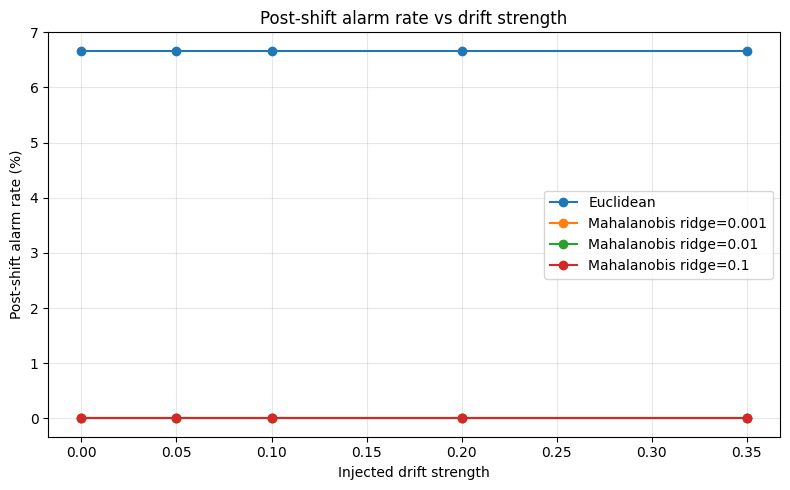

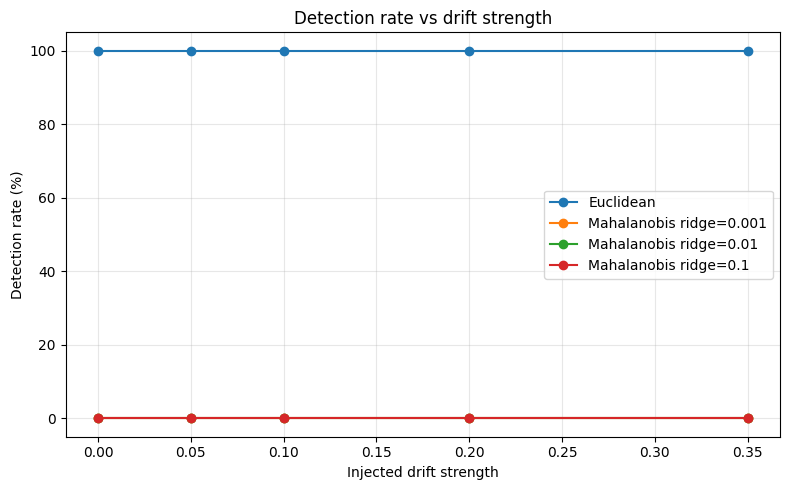

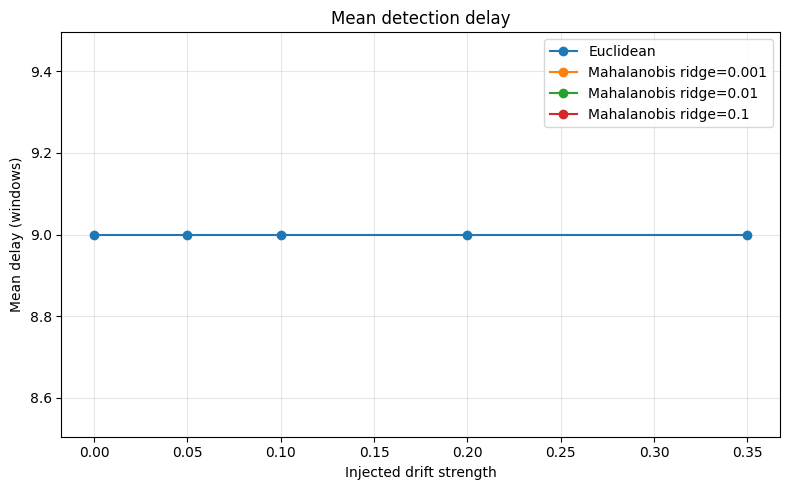

Saved Experiment 10 files:
results/LFW_Real_Data_Results/exp10_control_results.csv - 279 bytes
results/LFW_Real_Data_Results/exp10_detection_delay.png - 71908 bytes
results/LFW_Real_Data_Results/exp10_detection_rate.png - 73580 bytes
results/LFW_Real_Data_Results/exp10_detection_summary.csv - 1889 bytes
results/LFW_Real_Data_Results/exp10_post_shift_alarm_rate.png - 74799 bytes
results/LFW_Real_Data_Results/exp10_trial_results.csv - 8877 bytes


In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

OUTPUT_DIR = Path("results/LFW_Real_Data_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save trial-level and summary results
trial_df.to_csv(OUTPUT_DIR / "exp10_trial_results.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "exp10_detection_summary.csv", index=False)
control_results.to_csv(OUTPUT_DIR / "exp10_control_results.csv", index=False)

# Plot 1: post-shift alarm rate by drift strength
for metric, ylabel, filename, title in [
    (
        "post_alarm_pct",
        "Post-shift alarm rate (%)",
        "exp10_post_shift_alarm_rate.png",
        "Post-shift alarm rate vs drift strength"
    ),
    (
        "detection_pct",
        "Detection rate (%)",
        "exp10_detection_rate.png",
        "Detection rate vs drift strength"
    ),
    (
        "mean_delay_windows",
        "Mean delay (windows)",
        "exp10_detection_delay.png",
        "Mean detection delay"
    )
]:
    plt.figure(figsize=(8, 5))

    for (detector, ridge), group in summary_df.groupby(
        ["detector", "ridge"], dropna=False
    ):
        group = group.sort_values("drift_strength")
        label = (
            "Euclidean" if detector == "Euclidean"
            else f"Mahalanobis ridge={ridge:g}"
        )
        plt.plot(
            group["drift_strength"],
            group[metric],
            marker="o",
            label=label
        )

    plt.xlabel("Injected drift strength")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=200)
    plt.show()

print("Saved Experiment 10 files:")
for path in sorted(OUTPUT_DIR.glob("exp10_*")):
    print(path, "-", path.stat().st_size, "bytes")

In [9]:
from pathlib import Path
from datetime import date

report = f"""# Experiment 10: Improved Drift Evaluation Methodology

## 1. Objective

Evaluate whether Euclidean and Mahalanobis detectors distinguish
controlled embedding-space shifts from ordinary variation.

## 2. Dataset

- Dataset: Labeled Faces in the Wild (LFW)
- Images: {len(df)}
- Embedding dimensions: {X.shape[1]}
- Identity classes: {df["identity_label"].nunique()}
- Embedding extractor: Generic Vision Transformer (ViT)

## 3. Data partitioning

| Pool | Images |
|---|---:|
| Reference | {len(reference_idx)} |
| Calibration | {len(calibration_idx)} |
| Control | {len(control_idx)} |
| Evaluation | {len(evaluation_idx)} |

The four pools have no overlapping image indices. All contain the same
identity classes, so this is not an identity-disjoint generalisation test.

Standardisation statistics were fitted using the reference pool only.
Calibration thresholds were fixed before control and shifted evaluation.

## 4. Experimental configuration

- Window size: {WINDOW_SIZE}
- Calibration quantile: {CALIBRATION_QUANTILE}
- Mahalanobis ridge values: {RIDGE_VALUES}
- Drift strengths: {DRIFT_STRENGTHS}
- Drift directions: {N_DIRECTIONS}
- Evaluation windows: {len(W_evaluation)}
- Shift begins at window: {DRIFT_START}

## 5. Independent no-shift control

| Detector | Ridge | Threshold | Control alarms | Control rate |
|---|---:|---:|---:|---:|
"""

for _, row in control_results.iterrows():
    ridge = "-" if pd.isna(row["ridge"]) else f'{row["ridge"]:.3f}'
    report += (
        f'| {row["detector"]} | {ridge} | {row["threshold"]:.4f} | '
        f'{row["control_alarms"]}/{row["control_windows"]} | '
        f'{row["control_alarm_rate"]:.2%} |\\n'
    )

report += """
## 6. Results

The Euclidean detector reports alarms in the post-shift portion even
when the injected drift strength is zero. Its reported detection rate
therefore cannot be interpreted as successful drift detection.

The tested Mahalanobis configurations report no detections under the
current detection definition, including at the strongest tested shift.
This suggests that the present setup does not reliably distinguish
the injected perturbations from the detector's threshold behaviour.

The results are descriptive. The same evaluation windows are reused
across directions and strengths, so the trials are not independent
real-world observations.

## 7. Limitations

1. LFW images do not constitute a chronological biometric stream.
2. The feature extractor is a generic ViT, not a validated face-recognition model.
3. Shifts are synthetic perturbations of standardised embedding-space window means.
4. Only 30 windows are available per pool; estimates are uncertain.
5. All pools contain the same identities.
6. Ten drift directions reuse the same underlying evaluation windows.
7. A post-shift alarm is not proof that drift was detected.
8. No statistical-significance claim is made.

## 8. Conclusion

This experiment does not establish reliable drift detection. It identifies
a mismatch between the current injected shifts, score distributions,
thresholds, and detection metric. Further work should inspect raw scores,
validate the perturbation scale, use larger independent evaluation sets,
and evaluate identity-disjoint and realistic temporal/domain-shift scenarios.

## 9. Reproducibility

Trial-level results, summary tables, control results, and plots are saved
under `results/LFW_Real_Data_Results/`.

Report generated: """ + date.today().isoformat() + "\\n"

report_path = Path("Experiment_10_Improved_Evaluation_Report.md")
report_path.write_text(report, encoding="utf-8")

print("Report created:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")

Report created: Experiment_10_Improved_Evaluation_Report.md
Report size: 3131 bytes


In [10]:
from pathlib import Path
import zipfile
from google.colab import files

output_dir = Path("results/LFW_Real_Data_Results")

required_files = [
    Path("Experiment_10_Improved_Evaluation_Report.md"),
    output_dir / "exp10_trial_results.csv",
    output_dir / "exp10_detection_summary.csv",
    output_dir / "exp10_control_results.csv",
    output_dir / "exp10_post_shift_alarm_rate.png",
    output_dir / "exp10_detection_rate.png",
    output_dir / "exp10_detection_delay.png",
]

missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

zip_path = Path("Experiment_10_Artifacts.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in required_files:
        z.write(path, arcname=str(path))

print("ZIP created:", zip_path)
print("Files included:", len(required_files))
print("ZIP size:", zip_path.stat().st_size, "bytes")

files.download(str(zip_path))

ZIP created: Experiment_10_Artifacts.zip
Files included: 7
ZIP size: 177298 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>